# Redes neuronales con Python

Notebook adaptado del artículo **«Redes neuronales con Python»** de **Joaquín Amat Rodrigo**, publicado en
[cienciadedatos.net](https://cienciadedatos.net/documentos/py35-redes-neuronales-python).

> La obra original se distribuye bajo licencia [Creative Commons Attribution-NonCommercial-ShareAlike 4.0 (CC BY-NC-SA 4.0)](https://creativecommons.org/licenses/by-nc-sa/4.0/deed.es). Esta adaptación a formato notebook se comparte bajo la misma licencia. Los textos explicativos están redactados a partir del contenido del artículo y el código sigue los mismos pasos y parámetros; para la versión original completa consulta el enlace anterior.

**Contenido**

1. Introducción
2. Redes neuronales (estructura, neurona, activación, función de coste, múltiples capas, entrenamiento, preprocesado, hiperparámetros)
3. Modelos de redes neuronales en Scikit-learn
4. Ejemplo de clasificación
5. Caso de uso: predicción del precio de viviendas
6. Información de sesión
7. Bibliografía
8. Cómo citar

## 1. Introducción

Las redes neuronales y el *deep learning* forman un campo muy amplio. Conviene distinguir entre dos niveles:

- **Perceptrones multicapa (MLP) sencillos**: redes densas con pocas capas, aplicables a datos tabulares. Se entrenan sin problema en CPU con librerías como **scikit-learn** o **H2O**.
- **Modelos de *deep learning*** (redes convolucionales, recurrentes, LSTM, *transformers*…): requieren grandes volúmenes de datos, normalmente GPU y frameworks especializados como **Keras**, **TensorFlow** o **PyTorch**.

Este documento se centra en el primer grupo: explica los fundamentos teóricos de las redes neuronales y muestra cómo entrenarlas con `MLPClassifier` y `MLPRegressor` de scikit-learn.

## 2. Redes neuronales

### 2.1 Estructura de la red

Una red neuronal está formada por **neuronas** (unidades) organizadas en **capas**:

- **Capa de entrada**: recibe los valores de los predictores. Tiene una neurona por variable.
- **Capas ocultas**: transforman la información. Su número y tamaño definen la arquitectura.
- **Capa de salida**: genera la predicción (una neurona en regresión o clasificación binaria; una por clase en clasificación multiclase).

Las neuronas de capas consecutivas se conectan mediante **pesos**, que son los parámetros que la red aprende. Un modelo de regresión lineal puede verse como la red más simple posible: una capa de entrada conectada directamente a una neurona de salida, donde cada peso equivale a un coeficiente y el **sesgo** (*bias*) equivale a la ordenada en el origen:

$$\hat{y} = w_0 + w_1 x_1 + w_2 x_2 + \dots + w_p x_p$$

### 2.2 La neurona (unidad)

Cada neurona realiza dos operaciones:

1. Calcula una **combinación lineal** de sus entradas ponderadas por los pesos, más el sesgo:
$$z = b + \sum_{i=1}^{n} w_i x_i$$
2. Aplica una **función de activación** $g$ sobre ese valor: $a = g(z)$.

El valor $a$ es la salida de la neurona y se convierte en entrada de las neuronas de la siguiente capa.

### 2.3 Función de activación

La función de activación introduce **no linealidad**. Sin ella, por muchas capas que se apilasen, la red seguiría siendo equivalente a un modelo lineal, ya que la composición de transformaciones lineales es otra transformación lineal.

#### Rectified linear unit (ReLU)
$$\text{ReLU}(z) = \max(0, z)$$
Devuelve el propio valor si es positivo y cero en caso contrario. Es la **opción por defecto más habitual en capas ocultas** por su sencillez y buen comportamiento durante el entrenamiento.

#### Sigmoide
$$\sigma(z) = \frac{1}{1 + e^{-z}}$$
Transforma cualquier valor al rango $(0, 1)$, por lo que se interpreta como probabilidad. Es útil en la **capa de salida de problemas de clasificación binaria**. En capas ocultas tiende a saturarse y frenar el aprendizaje.

#### Tangente hiperbólica (Tanh)
$$\tanh(z) = \frac{e^{z} - e^{-z}}{e^{z} + e^{-z}}$$
Similar a la sigmoide pero con rango $(-1, 1)$ y centrada en cero.

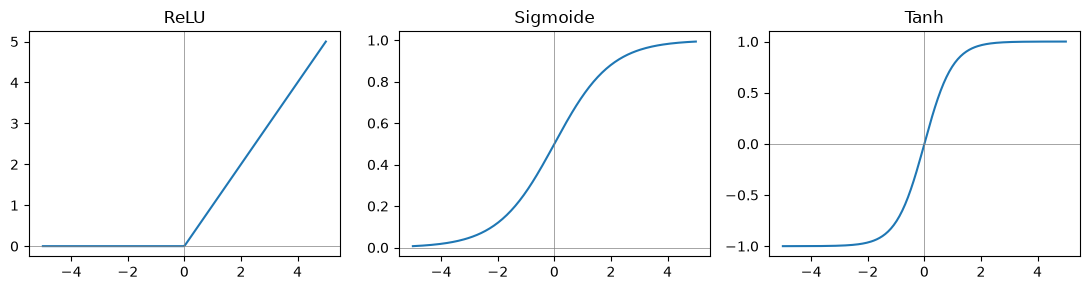

In [1]:
import numpy as np
import matplotlib.pyplot as plt

z = np.linspace(-5, 5, 200)
funciones = {
    'ReLU': np.maximum(0, z),
    'Sigmoide': 1 / (1 + np.exp(-z)),
    'Tanh': np.tanh(z),
}

fig, axs = plt.subplots(1, 3, figsize=(11, 3))
for ax, (nombre, valores) in zip(axs, funciones.items()):
    ax.plot(z, valores)
    ax.axhline(0, color='grey', lw=0.5)
    ax.axvline(0, color='grey', lw=0.5)
    ax.set_title(nombre)
fig.tight_layout();

### 2.4 Función de coste (*loss function*)

La función de coste, también llamada *función de pérdida*, *loss function* o *cost function*, mide lo lejos que están las predicciones de los valores reales. El entrenamiento consiste en encontrar los pesos que la minimizan.

#### Error cuadrático medio (MSE)
$$\text{MSE} = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2$$
La más empleada en regresión. Al elevar al cuadrado penaliza mucho los errores grandes; el modelo tiende a predecir la **media**.

#### Error medio absoluto (MAE)
$$\text{MAE} = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i|$$
Más robusta frente a valores atípicos; el modelo tiende a predecir la **mediana**.

#### Log loss, logistic loss o cross-entropy loss
$$\text{LogLoss} = -\frac{1}{n}\sum_{i=1}^{n}\sum_{k=1}^{K} y_{ik}\,\log(\hat{p}_{ik})$$
Se utiliza en clasificación. Penaliza con fuerza las predicciones que asignan probabilidad baja a la clase verdadera.

### 2.5 Múltiples capas

Al encadenar varias capas ocultas, la salida de cada capa es la entrada de la siguiente. Este tipo de red se conoce como **perceptrón multicapa** (*multilayer perceptron*, MLP). Con funciones de activación no lineales y suficientes neuronas, un MLP es un **aproximador universal**: puede aproximar cualquier función continua con la precisión deseada. Cada capa adicional permite combinar las representaciones aprendidas por la anterior y capturar relaciones más complejas.

### 2.6 Entrenamiento

Entrenar una red consiste en ajustar sus pesos y sesgos para minimizar la función de coste. Se repite el siguiente ciclo:

1. **Propagación hacia delante** (*forward pass*): se calculan las predicciones con los pesos actuales.
2. **Cálculo del error** con la función de coste.
3. **Backpropagation**: se obtiene el gradiente de la función de coste respecto a cada peso, aplicando la **regla de la cadena** desde la capa de salida hacia atrás.
4. **Actualización de los pesos** mediante descenso de gradiente.

#### Backpropagation
Permite calcular de forma eficiente cuánto contribuye cada peso al error total, reutilizando los cálculos de las capas posteriores.

#### Descenso de gradiente
Cada peso se desplaza en sentido contrario a su gradiente, en una magnitud controlada por la tasa de aprendizaje $\eta$:
$$w \leftarrow w - \eta \, \frac{\partial L}{\partial w}$$

En la práctica se usa el **descenso de gradiente estocástico** (SGD) con *mini-batches*: en cada iteración el gradiente se estima con un subconjunto de observaciones. Una **época** (*epoch*) es una pasada completa por todos los datos de entrenamiento.

Como el proceso es sensible a la escala de las variables, los predictores continuos deben **estandarizarse** antes de entrenar.

### 2.7 Preprocesado

Las redes neuronales solo trabajan con valores numéricos y son sensibles a la magnitud de las variables:

- **Variables categóricas**: se transforman con **one-hot encoding**, creando una variable binaria (*dummy*) por cada nivel.
- **Variables numéricas**:
  - **Centrado y estandarización (Z-score)**: $\;x' = \dfrac{x - \bar{x}}{s}$, media 0 y desviación típica 1.
  - **Normalización min-max**: $\;x' = \dfrac{x - x_{min}}{x_{max} - x_{min}}$, valores en $[0, 1]$.

Las variables binarias generadas por one-hot encoding **no** deben escalarse después.

### 2.8 Hiperparámetros

La flexibilidad de las redes neuronales viene acompañada de muchos hiperparámetros que hay que ajustar.

#### Número y tamaño de capas
Más capas y neuronas aumentan la capacidad del modelo, pero también el riesgo de sobreajuste y el coste computacional. Para datos tabulares suele bastar con una o dos capas ocultas.

#### Learning rate
Controla el tamaño de cada paso en el descenso de gradiente. Si es muy alto, el algoritmo puede oscilar o divergir; si es muy bajo, el entrenamiento es lento y puede quedarse en mínimos locales. Una estrategia común es reducirlo de forma progresiva a medida que avanza el entrenamiento.

#### Algoritmo de optimización
- **L-BFGS**: método de cuasi-Newton que converge rápido y bien en conjuntos de datos pequeños.
- **Adam** o **RMSprop**: variantes de SGD con tasa de aprendizaje adaptativa, adecuadas para conjuntos de datos grandes.

#### Regularización
##### Penalización L1 y L2
Se añade a la función de coste un término que penaliza la magnitud de los pesos (suma de valores absolutos en L1, suma de cuadrados en L2). Así se reduce la complejidad efectiva del modelo y el sobreajuste. En scikit-learn se controla con `alpha` (penalización L2).

##### Dropout
Durante el entrenamiento se desactiva aleatoriamente una fracción de neuronas en cada iteración, lo que obliga a la red a no depender de neuronas concretas. Valores típicos: entre 0.2 y 0.5. (No está disponible en los MLP de scikit-learn.)

## 3. Modelos de redes neuronales en Scikit-learn

Scikit-learn ofrece `MLPRegressor` (regresión) y `MLPClassifier` (clasificación). Sus argumentos principales son:

| Argumento | Descripción |
|---|---|
| `hidden_layer_sizes` | Tupla con el número de neuronas de cada capa oculta. Por defecto `(100,)`. |
| `activation` | Función de activación de las capas ocultas: `'identity'`, `'logistic'`, `'tanh'` o `'relu'` (por defecto). |
| `solver` | Algoritmo de optimización: `'lbfgs'` (datasets pequeños), `'sgd'` o `'adam'` (por defecto). |
| `alpha` | Intensidad de la regularización L2. Por defecto `0.0001`. |
| `batch_size` | Tamaño del mini-batch en `'sgd'` y `'adam'`. |
| `learning_rate` | Estrategia de la tasa de aprendizaje con `'sgd'`: `'constant'`, `'invscaling'`(se reduce progresivamente el learning rate en cada iteración t)o `'adaptive'`(mantiene constante el valor especificado en el argumento learning_rate_init siempre y cuando el modelo siga mejorando. Si entre dos épocas consecutivas el modelo no mejora un mínimo definido en el argumento tol, el learning rate se divide por 5. |
| `learning_rate_init` | Tasa de aprendizaje inicial (`'sgd'` y `'adam'`). Por defecto `0.001`. |
| `max_iter` | Número máximo de iteraciones (épocas en `'sgd'`/`'adam'`). |
| `shuffle` | Si se barajan las observaciones en cada iteración. |
| `random_state` | Semilla para la inicialización de pesos y el muestreo. |
| `tol` | Tolerancia para considerar que el algoritmo ha convergido. |
| `early_stopping` | Detiene el entrenamiento si no mejora una métrica de validación un mínimo de `tol`. |
| `validation_fraction` | Proporción de datos de entrenamiento usada como validación con `early_stopping`. |
| `n_iter_no_change` | Número de iteraciones sin mejora antes de detener el entrenamiento. |

## 4. Ejemplo de clasificación

Se simulan observaciones en dos dimensiones pertenecientes a tres grupos y se entrena una red neuronal para clasificarlas. El objetivo es ver cómo influyen la arquitectura y los hiperparámetros en las regiones de decisión aprendidas.

### 4.1 Librerías

In [2]:
# Tratamiento de datos
import numpy as np
import pandas as pd
from sklearn.datasets import make_blobs

# Gráficos
import matplotlib.pyplot as plt
import seaborn as sns

# Modelado
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from multiprocessing import cpu_count

# Configuración warnings
import warnings
warnings.filterwarnings('ignore')

### 4.2 Datos

Se generan 500 observaciones con dos predictores repartidas en tres grupos.

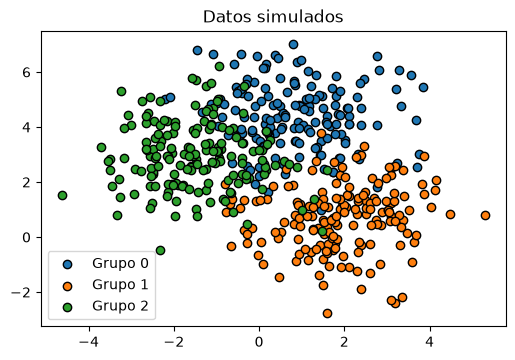

In [3]:
X, y = make_blobs(
    n_samples    = 500,
    n_features   = 2,
    centers      = 3,
    cluster_std  = 1.2,
    shuffle      = True,
    random_state = 0
)

fig, ax = plt.subplots(figsize=(6, 3.84))
for i in np.unique(y):
    ax.scatter(x=X[y == i, 0], y=X[y == i, 1], c=f'C{i}', marker='o', edgecolor='black', label=f'Grupo {i}')
ax.set_title('Datos simulados')
ax.legend();

### 4.3 Arquitectura de la red

Se entrenan cuatro redes de tamaño creciente para comparar la complejidad de las regiones de clasificación que aprenden. Para visualizar las regiones se predice la clase de cada punto de una malla que cubre el espacio de los predictores.

In [4]:
# Modelos
modelo_1 = MLPClassifier(hidden_layer_sizes=(5,), learning_rate_init=0.01,
                         solver='lbfgs', max_iter=1000, random_state=123)
modelo_2 = MLPClassifier(hidden_layer_sizes=(10,), learning_rate_init=0.01,
                         solver='lbfgs', max_iter=1000, random_state=123)
modelo_3 = MLPClassifier(hidden_layer_sizes=(20, 20), learning_rate_init=0.01,
                         solver='lbfgs', max_iter=5000, random_state=123)
modelo_4 = MLPClassifier(hidden_layer_sizes=(50, 50, 50), learning_rate_init=0.01,
                         solver='lbfgs', max_iter=5000, random_state=123)

modelos = [modelo_1, modelo_2, modelo_3, modelo_4]
for m in modelos:
    m.fit(X=X, y=y)

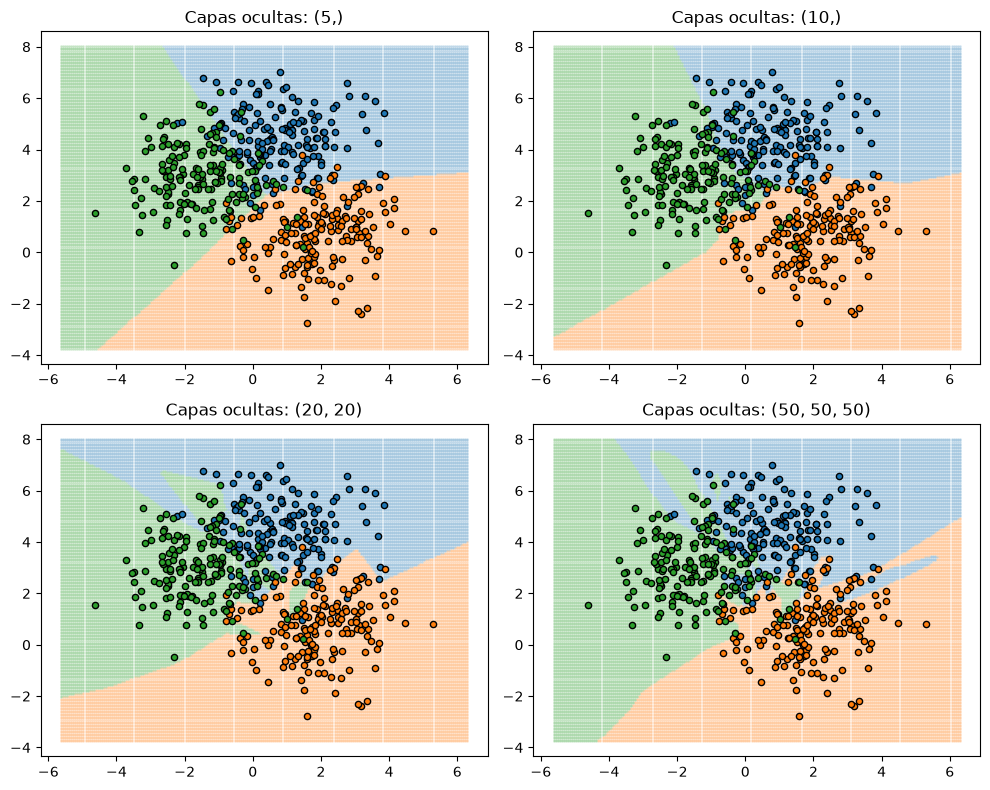

In [5]:
# Malla de valores para representar las regiones de clasificación
grid_x1 = np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 200)
grid_x2 = np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 200)
xx, yy = np.meshgrid(grid_x1, grid_x2)
X_grid = np.column_stack([xx.flatten(), yy.flatten()])

def plot_regiones(modelo, ax, titulo):
    # Dibuja las regiones de clasificación de un modelo y las observaciones
    y_pred_grid = modelo.predict(X_grid)
    for i in np.unique(y_pred_grid):
        ax.scatter(x=X_grid[y_pred_grid == i, 0], y=X_grid[y_pred_grid == i, 1],
                   c=f'C{i}', alpha=0.15, s=1)
    for i in np.unique(y):
        ax.scatter(x=X[y == i, 0], y=X[y == i, 1], c=f'C{i}', marker='o',
                   edgecolor='black', s=20)
    ax.set_title(titulo)

fig, axs = plt.subplots(2, 2, figsize=(10, 8))
for ax, modelo in zip(axs.flatten(), modelos):
    plot_regiones(modelo, ax, f'Capas ocultas: {modelo.hidden_layer_sizes}')
fig.tight_layout();

Las redes pequeñas generan fronteras de decisión simples, casi lineales. A medida que aumentan el número de capas y neuronas, las regiones se vuelven más complejas y la red se ajusta cada vez más a las observaciones de entrenamiento, lo que puede derivar en sobreajuste.

### 4.4 Optimización de hiperparámetros

Elegir a ojo la arquitectura y el resto de hiperparámetros no es fiable. Lo habitual es compararlos mediante **validación cruzada**. Primero se analiza el efecto de cada hiperparámetro por separado y después se realiza una búsqueda conjunta.

**Número de neuronas**

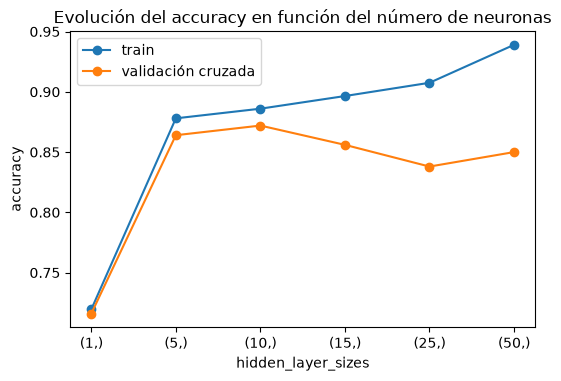

In [6]:
param_grid = {'hidden_layer_sizes': [(1,), (5,), (10,), (15,), (25,), (50,)]}

grid = GridSearchCV(
    estimator = MLPClassifier(
                    learning_rate_init = 0.01,
                    solver             = 'lbfgs',
                    alpha              = 0,
                    max_iter           = 5000,
                    random_state       = 123
                ),
    param_grid         = param_grid,
    scoring            = 'accuracy',
    cv                 = 5,
    refit              = True,
    return_train_score = True
)
_ = grid.fit(X, y)

resultados = pd.DataFrame(grid.cv_results_)
etiquetas = resultados['param_hidden_layer_sizes'].astype(str)

fig, ax = plt.subplots(figsize=(6, 3.84))
ax.plot(etiquetas, resultados['mean_train_score'], marker='o', label='train')
ax.plot(etiquetas, resultados['mean_test_score'], marker='o', label='validación cruzada')
ax.set_xlabel('hidden_layer_sizes')
ax.set_ylabel('accuracy')
ax.set_title('Evolución del accuracy en función del número de neuronas')
ax.legend();

**Learning rate**

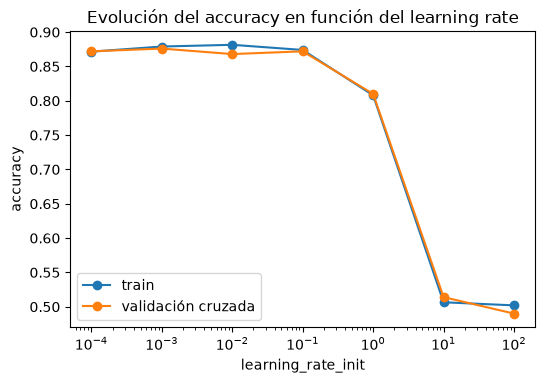

In [7]:
param_grid = {'learning_rate_init': [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]}

grid = GridSearchCV(
    estimator = MLPClassifier(
                    hidden_layer_sizes = (10,),
                    solver             = 'adam',
                    alpha              = 0,
                    max_iter           = 5000,
                    random_state       = 123
                ),
    param_grid         = param_grid,
    scoring            = 'accuracy',
    cv                 = 5,
    refit              = True,
    return_train_score = True
)
_ = grid.fit(X, y)

resultados = pd.DataFrame(grid.cv_results_)

fig, ax = plt.subplots(figsize=(6, 3.84))
ax.plot(resultados['param_learning_rate_init'].astype(float), resultados['mean_train_score'], marker='o', label='train')
ax.plot(resultados['param_learning_rate_init'].astype(float), resultados['mean_test_score'], marker='o', label='validación cruzada')
ax.set_xscale('log')
ax.set_xlabel('learning_rate_init')
ax.set_ylabel('accuracy')
ax.set_title('Evolución del accuracy en función del learning rate')
ax.legend();

Con tasas de aprendizaje muy altas el algoritmo no converge y la capacidad predictiva cae de forma drástica.

**Búsqueda conjunta (aleatoria)**

Cuando el espacio de búsqueda es grande, `RandomizedSearchCV` evalúa un número limitado de combinaciones elegidas al azar, lo que reduce mucho el tiempo de cómputo.

In [8]:
param_distributions = {
    'hidden_layer_sizes': [(10,), (10, 10), (20, 20)],
    'alpha':              np.logspace(-3, 3, 7),
    'learning_rate_init': [0.001, 0.01, 0.1],
}

grid = RandomizedSearchCV(
    estimator  = MLPClassifier(solver='lbfgs', max_iter=2000),
    param_distributions = param_distributions,
    n_iter     = 50,
    scoring    = 'accuracy',
    n_jobs     = max(cpu_count() - 1, 1),
    cv         = 3,
    verbose    = 0,
    random_state = 123,
    return_train_score = True
)
_ = grid.fit(X=X, y=y)

resultados = pd.DataFrame(grid.cv_results_)
resultados.filter(regex='(param.*|mean_t|std_t)') \
    .drop(columns='params') \
    .sort_values('mean_test_score', ascending=False) \
    .head(10)

,param_learning_rate_init,param_hidden_layer_sizes,param_alpha,mean_test_score,std_test_score,mean_train_score,std_train_score
34,0.100,"(10, 10)",10.0,0.869911,0.043076,0.877980,0.018836
18,0.001,"(10, 10)",1.0,0.869899,0.047867,0.899978,0.019906
46,0.010,"(10,)",100.0,0.869899,0.042016,0.873973,0.021077
49,0.100,"(10,)",100.0,0.869899,0.042016,0.873973,0.021077
30,0.010,"(10,)",10.0,0.867915,0.037310,0.875981,0.020949
21,0.100,"(20, 20)",10.0,0.865919,0.037716,0.878978,0.023269
7,0.010,"(10, 10)",10.0,0.865919,0.037716,0.877977,0.022883
35,0.100,"(10,)",0.1,0.865907,0.045794,0.893978,0.023255
41,0.001,"(10,)",10.0,0.863923,0.035070,0.875978,0.021527
1,0.001,"(10, 10)",10.0,0.863923,0.035070,0.880977,0.024650


Mejores hiperparámetros encontrados: {'learning_rate_init': 0.1, 'hidden_layer_sizes': (10, 10), 'alpha': np.float64(10.0)}


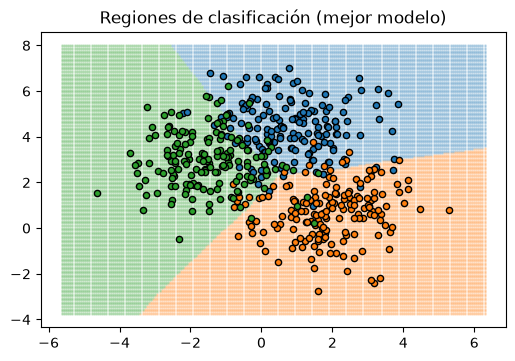

In [9]:
print('Mejores hiperparámetros encontrados:', grid.best_params_)

modelo = grid.best_estimator_

fig, ax = plt.subplots(figsize=(6, 3.84))
plot_regiones(modelo, ax, 'Regiones de clasificación (mejor modelo)');

La búsqueda favorece una red pequeña con una regularización relativamente alta (`alpha`), que genera fronteras suaves y generaliza mejor que las arquitecturas más grandes vistas antes.

## 5. Caso de uso: predicción del precio de viviendas

El conjunto de datos `SaratogaHouses` (paquete `mosaicData` de R) contiene el precio de 1728 viviendas de Saratoga County (Nueva York, EE. UU.) en 2006, junto con 15 características: superficie, antigüedad, número de habitaciones, tipo de calefacción, etc. El objetivo es predecir el precio a partir del resto de variables.

### 5.1 Librerías

In [10]:
# Tratamiento de datos
import numpy as np
import pandas as pd

# Gráficos
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocesado y modelado
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import make_column_selector
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error
from multiprocessing import cpu_count

# Configuración warnings
import warnings
warnings.filterwarnings('ignore')

### 5.2 Datos

In [11]:
url = ('https://raw.githubusercontent.com/JoaquinAmatRodrigo/'
       'Estadistica-machine-learning-python/master/data/SaratogaHouses.csv')
datos = pd.read_csv(url, sep=',')

# Se renombran las columnas para que sean más descriptivas
datos.columns = ['precio', 'metros_totales', 'antiguedad', 'precio_terreno',
                 'metros_habitables', 'universitarios', 'dormitorios',
                 'chimenea', 'banyos', 'habitaciones', 'calefaccion',
                 'consumo_calefacion', 'desague', 'vistas_lago',
                 'nueva_construccion', 'aire_acondicionado']
datos.head(4)

,precio,metros_totales,antiguedad,precio_terreno,metros_habitables,universitarios,dormitorios,chimenea,banyos,habitaciones,calefaccion,consumo_calefacion,desague,vistas_lago,nueva_construccion,aire_acondicionado
0,132500,0.09,42,50000,906,35,2,1,1.0,5,electric,electric,septic,No,No,No
1,181115,0.92,0,22300,1953,51,3,0,2.5,6,hot water/steam,gas,septic,No,No,No
2,109000,0.19,133,7300,1944,51,4,1,1.0,8,hot water/steam,gas,public/commercial,No,No,No
3,155000,0.41,13,18700,1944,51,3,1,1.5,5,hot air,gas,septic,No,No,No


### 5.3 Análisis exploratorio

Antes de entrenar un modelo conviene conocer los datos: tipo de cada variable, valores ausentes, distribución de la variable respuesta y de los predictores.

In [12]:
# Tipo de cada columna
datos.info()

<class 'pandas.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   precio              1728 non-null   int64  
 1   metros_totales      1728 non-null   float64
 2   antiguedad          1728 non-null   int64  
 3   precio_terreno      1728 non-null   int64  
 4   metros_habitables   1728 non-null   int64  
 5   universitarios      1728 non-null   int64  
 6   dormitorios         1728 non-null   int64  
 7   chimenea            1728 non-null   int64  
 8   banyos              1728 non-null   float64
 9   habitaciones        1728 non-null   int64  
 10  calefaccion         1728 non-null   str    
 11  consumo_calefacion  1728 non-null   str    
 12  desague             1728 non-null   str    
 13  vistas_lago         1728 non-null   str    
 14  nueva_construccion  1728 non-null   str    
 15  aire_acondicionado  1728 non-null   str    
dtypes: float64(2), in

In [13]:
# Número de valores ausentes por columna
datos.isna().sum().sort_values()

precio                0
metros_totales        0
antiguedad            0
precio_terreno        0
metros_habitables     0
universitarios        0
dormitorios           0
chimenea              0
banyos                0
habitaciones          0
calefaccion           0
consumo_calefacion    0
desague               0
vistas_lago           0
nueva_construccion    0
aire_acondicionado    0
dtype: int64

**Variable respuesta**

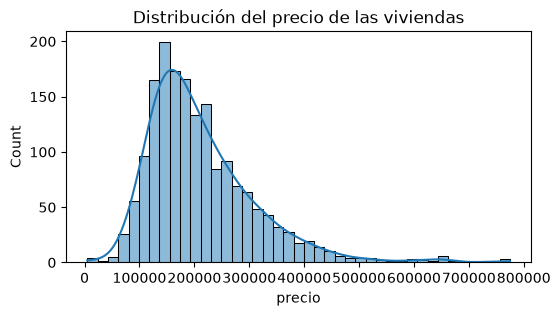

In [14]:
fig, ax = plt.subplots(figsize=(6, 3))
sns.histplot(data=datos, x='precio', kde=True, ax=ax)
ax.set_title('Distribución del precio de las viviendas')
ax.set_xlabel('precio');

**Variables numéricas**

In [15]:
datos.select_dtypes(include=['float64', 'int']).describe()

,precio,metros_totales,antiguedad,precio_terreno,metros_habitables,universitarios,dormitorios,chimenea,banyos,habitaciones
count,1728.000000,1728.000000,1728.000000,1728.000000,1728.000000,1728.000000,1728.000000,1728.000000,1728.000000,1728.000000
mean,211966.705440,0.500214,27.916088,34557.187500,1754.975694,55.567708,3.154514,0.601852,1.900174,7.041667
std,98441.391015,0.698680,29.209988,35021.168056,619.935553,10.333581,0.817351,0.556102,0.658352,2.316453
min,5000.000000,0.000000,0.000000,200.000000,616.000000,20.000000,1.000000,0.000000,0.000000,2.000000
25%,145000.000000,0.170000,13.000000,15100.000000,1300.000000,52.000000,3.000000,0.000000,1.500000,5.000000
50%,189900.000000,0.370000,19.000000,25000.000000,1634.500000,57.000000,3.000000,1.000000,2.000000,7.000000
75%,259000.000000,0.540000,34.000000,40200.000000,2137.750000,64.000000,4.000000,1.000000,2.500000,8.250000
max,775000.000000,12.200000,225.000000,412600.000000,5228.000000,82.000000,7.000000,4.000000,4.500000,12.000000


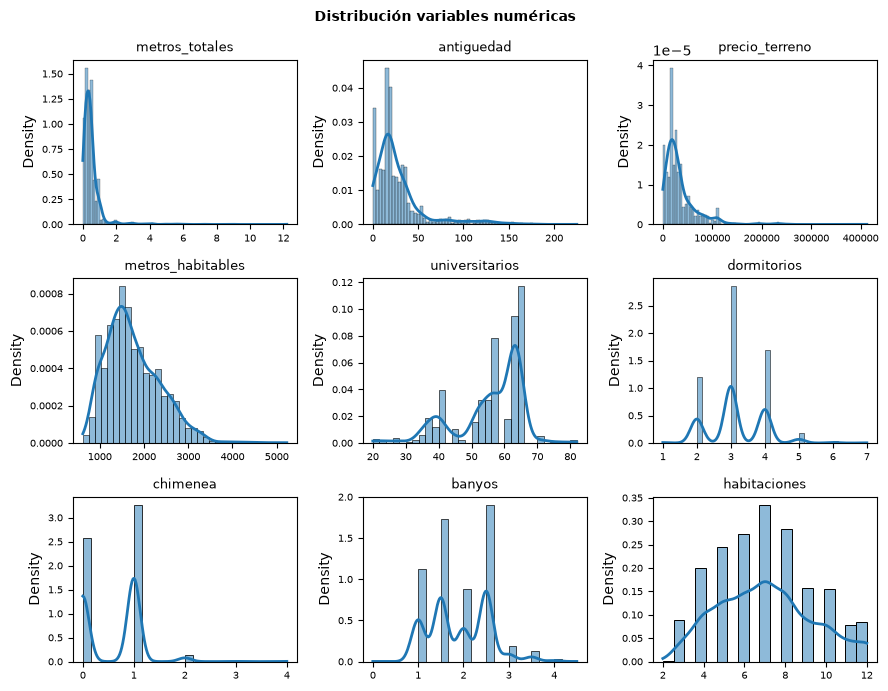

In [16]:
columnas_numericas = datos.select_dtypes(include=['float64', 'int']).columns.drop('precio')

fig, axs = plt.subplots(3, 3, figsize=(9, 7))
axs = axs.flatten()
for i, col in enumerate(columnas_numericas):
    sns.histplot(data=datos, x=col, kde=True, stat='density', ax=axs[i], line_kws={'linewidth': 2})
    axs[i].set_title(col, fontsize=9)
    axs[i].tick_params(labelsize=7)
    axs[i].set_xlabel('')
for ax in axs[len(columnas_numericas):]:
    ax.remove()
fig.suptitle('Distribución variables numéricas', fontsize=10, fontweight='bold')
fig.tight_layout();

La variable `chimenea`, aunque es numérica, toma muy pocos valores distintos, por lo que se trata mejor como categórica.

In [17]:
datos['chimenea'].value_counts()

chimenea
1    942
0    740
2     42
4      2
3      2
Name: count, dtype: int64

In [18]:
# Se convierte a texto y se agrupan los niveles poco frecuentes (2, 3 y 4) en "2_mas"
datos['chimenea'] = datos['chimenea'].astype(str)
datos['chimenea'] = datos['chimenea'].replace({'2': '2_mas', '3': '2_mas', '4': '2_mas'})
datos['chimenea'].value_counts()

chimenea
1        942
0        740
2_mas     46
Name: count, dtype: int64

**Variables cualitativas**

In [19]:
datos.select_dtypes(include=['object']).describe()

,chimenea,calefaccion,consumo_calefacion,desague,vistas_lago,nueva_construccion,aire_acondicionado
count,1728,1728,1728,1728,1728,1728,1728
unique,3,3,3,3,2,2,2
top,1,hot air,gas,public/commercial,No,No,No
freq,942,1121,1197,1213,1713,1647,1093


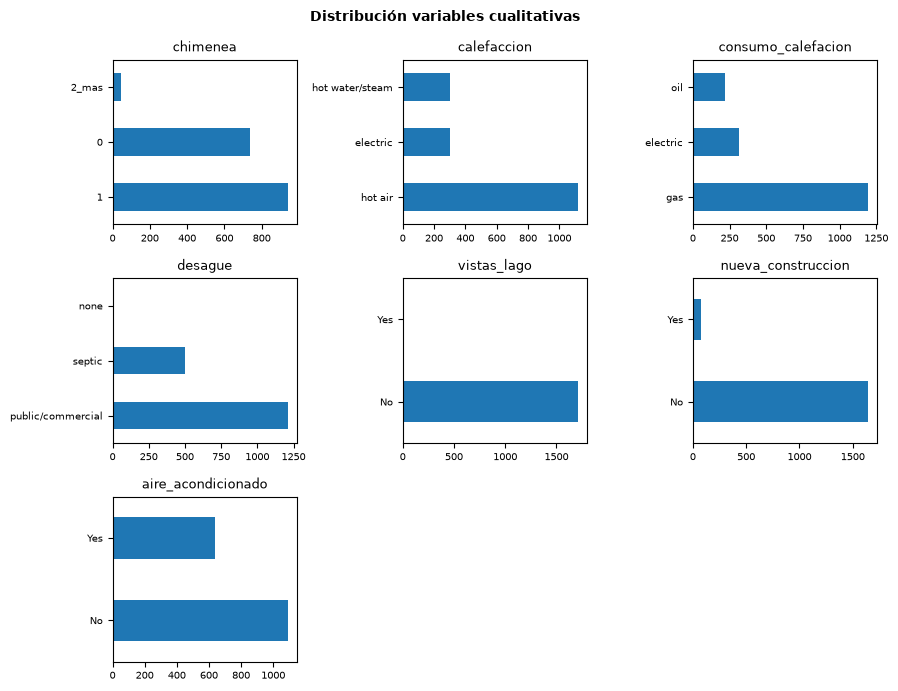

In [20]:
columnas_categoricas = datos.select_dtypes(include=['object']).columns

fig, axs = plt.subplots(3, 3, figsize=(9, 7))
axs = axs.flatten()
for i, col in enumerate(columnas_categoricas):
    datos[col].value_counts().plot.barh(ax=axs[i])
    axs[i].set_title(col, fontsize=9)
    axs[i].tick_params(labelsize=7)
    axs[i].set_ylabel('')
for ax in axs[len(columnas_categoricas):]:
    ax.remove()
fig.suptitle('Distribución variables cualitativas', fontsize=10, fontweight='bold')
fig.tight_layout();

### 5.4 División train y test

Se reserva un 20 % de las observaciones como conjunto de test para evaluar el modelo final.

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    datos.drop(columns='precio'),
    datos['precio'],
    train_size   = 0.8,
    random_state = 1234,
    shuffle      = True
)

Es conveniente comprobar que la variable respuesta se distribuye de forma similar en ambos conjuntos.

In [22]:
print('Partición de entrenamiento')
print('-----------------------')
print(y_train.describe())
print()
print('Partición de test')
print('-----------------------')
print(y_test.describe())

Partición de entrenamiento
-----------------------
count      1382.000000
mean     211436.516643
std       96846.639129
min       10300.000000
25%      145625.000000
50%      190000.000000
75%      255000.000000
max      775000.000000
Name: precio, dtype: float64

Partición de test
-----------------------
count       346.000000
mean     214084.395954
std      104689.155889
min        5000.000000
25%      139000.000000
50%      180750.000000
75%      271750.000000
max      670000.000000
Name: precio, dtype: float64


### 5.5 Preprocesado

Se estandarizan las variables numéricas y se aplica one-hot encoding a las categóricas. Con `ColumnTransformer` cada transformación se aplica solo a las columnas correspondientes. Los parámetros de las transformaciones se aprenden **solo** con los datos de entrenamiento y después se aplican al test, para evitar fugas de información.

In [23]:
# Identificación de columnas numéricas y categóricas
numeric_cols = X_train.select_dtypes(include=['float64', 'int']).columns.to_list()
cat_cols = X_train.select_dtypes(include=['object', 'category']).columns.to_list()

# Transformaciones
preprocessor = ColumnTransformer(
    [('scale', StandardScaler(), numeric_cols),
     ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)],
    remainder='passthrough',
    verbose_feature_names_out=False
).set_output(transform='pandas')

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)
X_train_prep.head(3)

,metros_totales,antiguedad,precio_terreno,metros_habitables,universitarios,dormitorios,banyos,habitaciones,chimenea_0,chimenea_1,...,consumo_calefacion_oil,desague_none,desague_public/commercial,desague_septic,vistas_lago_No,vistas_lago_Yes,nueva_construccion_No,nueva_construccion_Yes,aire_acondicionado_No,aire_acondicionado_Yes
1571,-0.061549,0.301597,-0.195148,1.320467,0.826826,1.011039,0.905289,2.128665,0.0,1.0,...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
832,-0.195573,-0.407560,-0.277982,0.194931,0.730235,1.011039,1.663079,1.264569,0.0,1.0,...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
1302,0.072475,-0.478476,-0.892092,-0.064313,-1.877728,1.011039,0.147500,-0.463623,1.0,0.0,...,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0


In [24]:
X_train_prep.info()

<class 'pandas.DataFrame'>
Index: 1382 entries, 1571 to 815
Data columns (total 26 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   metros_totales               1382 non-null   float64
 1   antiguedad                   1382 non-null   float64
 2   precio_terreno               1382 non-null   float64
 3   metros_habitables            1382 non-null   float64
 4   universitarios               1382 non-null   float64
 5   dormitorios                  1382 non-null   float64
 6   banyos                       1382 non-null   float64
 7   habitaciones                 1382 non-null   float64
 8   chimenea_0                   1382 non-null   float64
 9   chimenea_1                   1382 non-null   float64
 10  chimenea_2_mas               1382 non-null   float64
 11  calefaccion_electric         1382 non-null   float64
 12  calefaccion_hot air          1382 non-null   float64
 13  calefaccion_hot water/steam  138

### 5.6 Modelado

Para que el preprocesado se aprenda de nuevo en cada partición de la validación cruzada, se combina con el modelo en un `Pipeline`. Después se realiza una búsqueda aleatoria de hiperparámetros.

In [25]:
# Pipeline: preprocesado + modelo
pipe = Pipeline([
    ('preprocesado', preprocessor),
    ('modelo', MLPRegressor(solver='lbfgs', max_iter=1000))
])

# Espacio de búsqueda
param_distributions = {
    'modelo__hidden_layer_sizes': [(10,), (20,), (10, 10)],
    'modelo__alpha':              np.logspace(-3, 3, 10),
    'modelo__learning_rate_init': [0.001, 0.01],
}

grid = RandomizedSearchCV(
    estimator  = pipe,
    param_distributions = param_distributions,
    n_iter     = 50,
    scoring    = 'neg_mean_squared_error',
    n_jobs     = max(cpu_count() - 1, 1),
    cv         = 5,
    verbose    = 0,
    random_state = 123,
    return_train_score = True
)
_ = grid.fit(X=X_train, y=y_train)

resultados = pd.DataFrame(grid.cv_results_)
resultados.filter(regex='(param.*|mean_t|std_t)') \
    .drop(columns='params') \
    .sort_values('mean_test_score', ascending=False) \
    .head(10)

,param_modelo__learning_rate_init,param_modelo__hidden_layer_sizes,param_modelo__alpha,mean_test_score,std_test_score,mean_train_score,std_train_score
14,0.010,"(10, 10)",0.004642,-3.316762e+09,8.195774e+08,-2.371958e+09,2.524225e+08
30,0.010,"(10,)",10.000000,-3.335213e+09,6.139962e+08,-2.475297e+09,2.155089e+08
4,0.010,"(10,)",46.415888,-3.359458e+09,6.197307e+08,-2.619143e+09,1.278443e+08
41,0.001,"(10,)",10.000000,-3.359576e+09,8.136476e+08,-2.661419e+09,1.960571e+08
46,0.010,"(10,)",215.443469,-3.380297e+09,6.812255e+08,-2.677480e+09,2.331781e+08
0,0.001,"(10,)",0.464159,-3.384796e+09,7.601304e+08,-2.572766e+09,2.065344e+08
3,0.010,"(10,)",2.154435,-3.428132e+09,7.769632e+08,-2.566688e+09,1.790914e+08
28,0.010,"(10, 10)",0.464159,-3.448230e+09,5.901944e+08,-2.280306e+09,1.444678e+08
44,0.010,"(10,)",0.464159,-3.467824e+09,6.185861e+08,-2.595302e+09,3.182106e+08
6,0.001,"(10,)",0.100000,-3.471111e+09,6.546087e+08,-2.479240e+09,1.113718e+08


### 5.7 Error de test

Se evalúa el mejor modelo encontrado sobre el conjunto de test, que no ha intervenido en el entrenamiento ni en la selección de hiperparámetros.

In [26]:
modelo_final = grid.best_estimator_
predicciones = modelo_final.predict(X=X_test)
rmse = mean_squared_error(y_true=y_test, y_pred=predicciones) ** 0.5
print(f'Error de test (rmse): {rmse:.2f}')

Error de test (rmse): 69139.69


### 5.8 Conclusión

Combinando preprocesado, red neuronal y búsqueda de hiperparámetros con validación cruzada se obtiene un modelo con una capa oculta pequeña cuyo error de test (RMSE) se sitúa aproximadamente entre 60 000 y 70 000 dólares, según la ejecución. En el artículo original el mejor modelo tiene una capa oculta de 10 neuronas y `alpha ≈ 0.46`, con un RMSE de test de unos 62 800 (en el texto de la conclusión se cita 60 948).

Como `MLPRegressor` se crea sin `random_state`, la inicialización de los pesos cambia en cada ejecución y el resultado exacto puede variar. Para obtener resultados reproducibles basta con fijar `MLPRegressor(..., random_state=123)`.

In [27]:
modelo_final['modelo'].get_params()

{'activation': 'relu',
 'alpha': np.float64(0.004641588833612777),
 'batch_size': 'auto',
 'beta_1': 0.9,
 'beta_2': 0.999,
 'early_stopping': False,
 'epsilon': 1e-08,
 'hidden_layer_sizes': (10, 10),
 'learning_rate': 'constant',
 'learning_rate_init': 0.01,
 'loss': 'squared_error',
 'max_fun': 15000,
 'max_iter': 1000,
 'momentum': 0.9,
 'n_iter_no_change': 10,
 'nesterovs_momentum': True,
 'power_t': 0.5,
 'random_state': None,
 'shuffle': True,
 'solver': 'lbfgs',
 'tol': 0.0001,
 'validation_fraction': 0.1,
 'verbose': False,
 'warm_start': False}

## 6. Información de sesión

In [28]:
# !pip install session-info   # si no está instalado
try:
    import session_info
    session_info.show(html=False)
except ImportError:
    import sys, sklearn, matplotlib
    print('Python      :', sys.version.split()[0])
    print('numpy       :', np.__version__)
    print('pandas      :', pd.__version__)
    print('scikit-learn:', sklearn.__version__)
    print('matplotlib  :', matplotlib.__version__)
    print('seaborn     :', sns.__version__)

Python      : 3.13.18
numpy       : 2.5.3
pandas      : 3.0.5
scikit-learn: 1.9.1
matplotlib  : 3.11.2
seaborn     : 0.13.2
